# **MY PROJECT : EDA ON AMAZON DATASET**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path


# ***Load Dataset***

In [2]:
df = pd.read_csv("/content/amazon.csv")

# ***Data Overview***

In [3]:
df.info()
display(df.describe())
display(df.describe(include="object"))
display(df.dtypes)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           1465 non-null   object
 1   product_name         1465 non-null   object
 2   category             1465 non-null   object
 3   discounted_price     1465 non-null   object
 4   actual_price         1465 non-null   object
 5   discount_percentage  1465 non-null   object
 6   rating               1465 non-null   object
 7   rating_count         1463 non-null   object
 8   about_product        1465 non-null   object
 9   user_id              1465 non-null   object
 10  user_name            1465 non-null   object
 11  review_id            1465 non-null   object
 12  review_title         1465 non-null   object
 13  review_content       1465 non-null   object
 14  img_link             1465 non-null   object
 15  product_link         1465 non-null   object
dtypes: obj

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
count,1465,1465,1465,1465,1465,1465,1465,1463,1465,1465,1465,1465,1465,1465,1465,1465
unique,1351,1337,211,550,449,92,28,1143,1293,1194,1194,1194,1194,1212,1412,1465
top,B083342NKJ,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",Computers&Accessories|Accessories&Peripherals|...,₹199,₹999,50%,4.1,"9,378",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AHIKJUDTVJ4T6DV6IUGFYZ5LXMPA,AE55KTFVNXYFD5FPY...","$@|\|TO$|-|,Sethu madhav,Akash Thakur,Burger P...","R3F4T5TRYPTMIG,R3DQIEC603E7AY,R1O4Z15FD40PV5,R...","Worked on iPhone 7 and didn’t work on XR,Good ...","I am not big on camera usage, personally. I wa...",https://m.media-amazon.com/images/I/413sCRKobN...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
freq,3,5,233,53,120,56,244,9,6,10,10,10,10,8,3,1


,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
count,1465,1465,1465,1465,1465,1465,1465,1463,1465,1465,1465,1465,1465,1465,1465,1465
unique,1351,1337,211,550,449,92,28,1143,1293,1194,1194,1194,1194,1212,1412,1465
top,B083342NKJ,"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Wat...",Computers&Accessories|Accessories&Peripherals|...,₹199,₹999,50%,4.1,"9,378",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AHIKJUDTVJ4T6DV6IUGFYZ5LXMPA,AE55KTFVNXYFD5FPY...","$@|\|TO$|-|,Sethu madhav,Akash Thakur,Burger P...","R3F4T5TRYPTMIG,R3DQIEC603E7AY,R1O4Z15FD40PV5,R...","Worked on iPhone 7 and didn’t work on XR,Good ...","I am not big on camera usage, personally. I wa...",https://m.media-amazon.com/images/I/413sCRKobN...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
freq,3,5,233,53,120,56,244,9,6,10,10,10,10,8,3,1


,0
product_id,object
product_name,object
category,object
discounted_price,object
actual_price,object
discount_percentage,object
rating,object
rating_count,object
about_product,object
user_id,object


### ***Unique Products***

In [4]:
print('=== UNIQUE PRODUCTS ===')

print("Unique Product names:", df["product_name"].unique())
display(df["product_name"].value_counts().sort_values(ascending=False).head(3))

=== UNIQUE PRODUCTS ===
Unique Product names: ['Wayona Nylon Braided USB to Lightning Fast Charging and Data Sync Cable Compatible for iPhone 13, 12,11, X, 8, 7, 6, 5, iPad Air, Pro, Mini (3 FT Pack of 1, Grey)'
 'Ambrane Unbreakable 60W / 3A Fast Charging 1.5m Braided Type C Cable for Smartphones, Tablets, Laptops & other Type C devices, PD Technology, 480Mbps Data Sync, Quick Charge 3.0 (RCT15A, Black)'
 'Sounce Fast Phone Charging Cable & Data Sync USB Cable Compatible for iPhone 13, 12,11, X, 8, 7, 6, 5, iPad Air, Pro, Mini & iOS Devices'
 ...
 'Bajaj Majesty RX10 2000 Watts Heat Convector Room Heater (White, ISI Approved)'
 'Havells Ventil Air DSP 230mm Exhaust Fan (Pista Green)'
 'Borosil Jumbo 1000-Watt Grill Sandwich Maker (Black)']


,count
product_name,
"Fire-Boltt Ninja Call Pro Plus 1.83"" Smart Watch with Bluetooth Calling, AI Voice Assistance, 100 Sports Modes IP67 Rating, 240*280 Pixel High Resolution",5
"Fire-Boltt Phoenix Smart Watch with Bluetooth Calling 1.3"",120+ Sports Modes, 240*240 PX High Res with SpO2, Heart Rate Monitoring & IP67 Rating",4
"Amazonbasics Nylon Braided Usb-C To Lightning Cable, Fast Charging Mfi Certified Smartphone, Iphone Charger (6-Foot, Dark Grey)",3


# ***Data Cleaning***

In [5]:
print('=== CLEANING DATA ===')

# Clean discounted price (remove '₹' and commas, convert to decimal numbers)
df['discounted_price_num'] = (df['discounted_price']
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

# Clean actual price
df['actual_price_num'] = (
df['actual_price']
    .str.replace('₹', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

# Clean discount percentage (remove '%')
df['discount_pct_num'] = (
    df['discount_percentage'].str.replace('%', '', regex=False).astype(float)
)

# Convert ratings to numeric (ignoring any errors)
df['rating_num'] = pd.to_numeric(df['rating'], errors='coerce')

# Clean rating count (remove commas)
df['rating_count_num'] = pd.to_numeric(
    df['rating_count'].str.replace(',', '', regex=False), errors='coerce'
)

print('Data cleaning completed successfully!')
print(
    df[[
        'product_name',
        'discounted_price_num',
        'actual_price_num',
        'rating_num',
    ]].head(3)
)

=== CLEANING DATA ===
Data cleaning completed successfully!
                                        product_name  discounted_price_num  \
0  Wayona Nylon Braided USB to Lightning Fast Cha...                 399.0   
1  Ambrane Unbreakable 60W / 3A Fast Charging 1.5...                 199.0   
2  Sounce Fast Phone Charging Cable & Data Sync U...                 199.0   

   actual_price_num  rating_num  
0            1099.0         4.2  
1             349.0         4.0  
2            1899.0         3.9  


# ***Statistical Insights***



In [6]:
# data is cleaned using above Code
print('=== 3. STATISTICAL INSIGHTS ===')

# Summary statistics for prices and ratings
print(
    df[[
        'discounted_price_num',
        'actual_price_num',
        'discount_pct_num',
        'rating_num',
    ]].describe()
)

print('\n=== TOP 5 PRODUCT CATEGORIES ===')
top_categories = df['category'].value_counts().head(5)
print(top_categories)

=== 3. STATISTICAL INSIGHTS ===
       discounted_price_num  actual_price_num  discount_pct_num   rating_num
count           1465.000000       1465.000000       1465.000000  1464.000000
mean            3125.310874       5444.990635         47.691468     4.096585
std             6944.304394      10874.826864         21.635905     0.291674
min               39.000000         39.000000          0.000000     2.000000
25%              325.000000        800.000000         32.000000     4.000000
50%              799.000000       1650.000000         50.000000     4.100000
75%             1999.000000       4295.000000         63.000000     4.300000
max            77990.000000     139900.000000         94.000000     5.000000

=== TOP 5 PRODUCT CATEGORIES ===
category
Computers&Accessories|Accessories&Peripherals|Cables&Accessories|Cables|USBCables    233
Electronics|WearableTechnology|SmartWatches                                           76
Electronics|Mobiles&Accessories|Smartphones&BasicMobil

# ***Highest Discounted Products***

In [7]:
print('=== TOP 5 HIGHEST DISCOUNTED PRODUCTS ===')

top_discounts = df.sort_values(by='discount_pct_num', ascending=False).head(5)
print(top_discounts[[
        'product_name',
        'actual_price',
        'discounted_price',
        'discount_percentage',
    ]])

=== TOP 5 HIGHEST DISCOUNTED PRODUCTS ===
                                          product_name actual_price  \
695  rts [2 Pack] Mini USB C Type C Adapter Plug, T...       ₹4,999   
372  Fire-Boltt Ninja Call Pro Plus 1.83" Smart Wat...      ₹19,999   
380  Fire-Boltt Ninja Call Pro Plus 1.83" Smart Wat...      ₹19,999   
364  Fire-Boltt Ninja Call Pro Plus 1.83" Smart Wat...      ₹19,999   
368  Fire-Boltt Ninja Call Pro Plus 1.83" Smart Wat...      ₹19,999   

    discounted_price discount_percentage  
695             ₹294                 94%  
372           ₹1,799                 91%  
380           ₹1,799                 91%  
364           ₹1,799                 91%  
368           ₹1,799                 91%  


# ***Finding the Top 5 Best-Rated Products with High Reviews***

In [8]:
# Assuming Top Rating is 5.0
perfect_products = df[df['rating_num'] == 5.0]

top_popular_5 = perfect_products.sort_values(
    by='rating_count_num', ascending=False).head(5)

print('=== TOP 5 PRODUCTS WITH 5.0 RATING & MOST REVIEWS ===')
print(top_popular_5[['product_name', 'rating_count', 'discounted_price']])

=== TOP 5 PRODUCTS WITH 5.0 RATING & MOST REVIEWS ===
                                          product_name rating_count  \
775  Amazon Basics Wireless Mouse | 2.4 GHz Connect...           23   
174  Syncwire LTG to USB Cable for Fast Charging Co...            5   
324  REDTECH USB-C to Lightning Cable 3.3FT, [Apple...          NaN   

    discounted_price  
775             ₹499  
174             ₹399  
324             ₹249  


# ***Price comparision summery by top catagories***

In [9]:
category_pricing = (
    df.groupby('category')[['actual_price_num', 'discounted_price_num']]
    .mean()
    .round(2)
)
category_pricing.columns = [
    'Avg Actual Price (₹)',
    'Avg Discounted Price (₹)',
]

print('=== AVERAGE PRICES BY CATEGORY (TOP 5) ===')
print(category_pricing.head(5))

=== AVERAGE PRICES BY CATEGORY (TOP 5) ===
                                                    Avg Actual Price (₹)  \
category                                                                   
Car&Motorbike|CarAccessories|InteriorAccessorie...                4000.0   
Computers&Accessories|Accessories&Peripherals|A...                2699.0   
Computers&Accessories|Accessories&Peripherals|A...                 999.0   
Computers&Accessories|Accessories&Peripherals|A...                1249.5   
Computers&Accessories|Accessories&Peripherals|A...                1399.5   

                                                    Avg Discounted Price (₹)  
category                                                                      
Car&Motorbike|CarAccessories|InteriorAccessorie...                    2339.0  
Computers&Accessories|Accessories&Peripherals|A...                     221.5  
Computers&Accessories|Accessories&Peripherals|A...                     649.0  
Computers&Accessories|Accesso

# **Graphical Representations**






### ***Top product categories***

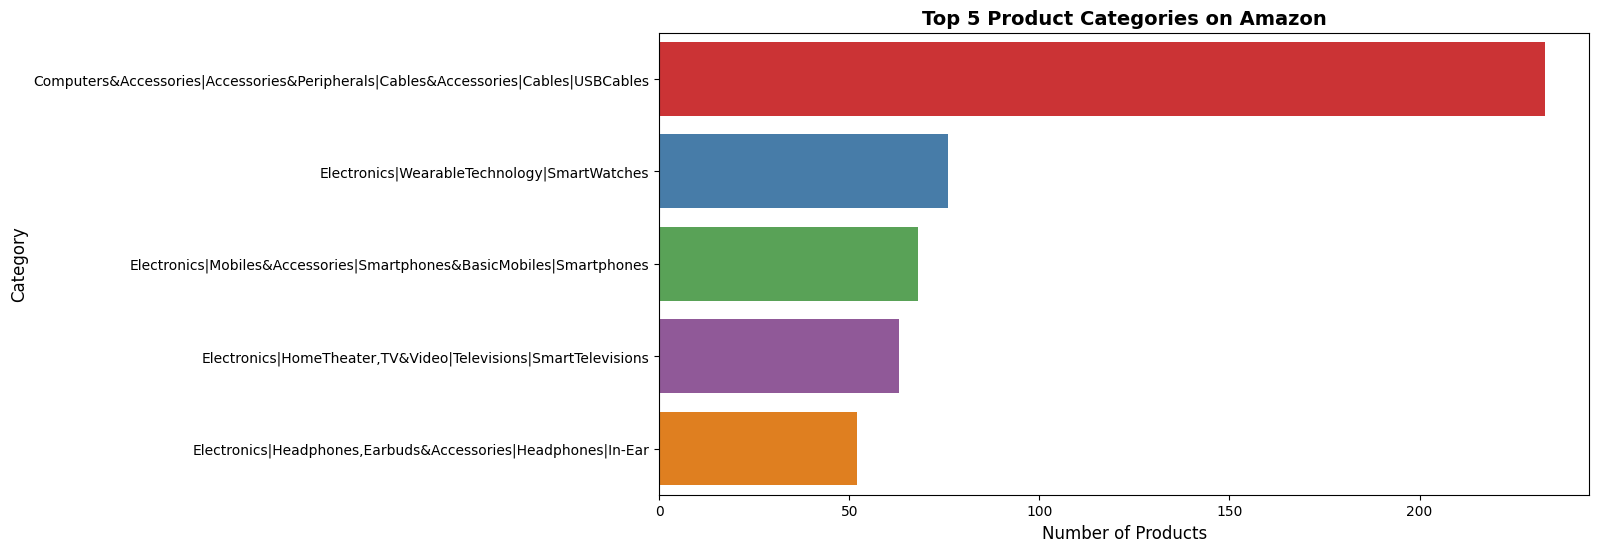

In [10]:
from pandas.core.indexes import category
# Prepare data for top 5 categories
top_cats_df = df['category'].value_counts().head(5).reset_index()
top_cats_df.columns = ['category', 'count']

plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_cats_df, x='count', y='category', palette='Set1', hue='category')

# Labels and Title
plt.title('Top 5 Product Categories on Amazon', fontsize=14, fontweight='bold')
plt.xlabel('Number of Products', fontsize=12)
plt.ylabel('Category', fontsize=12)

# Save and Display
plt.savefig('top_categories.png', bbox_inches='tight')
plt.show()

### ***Product Rating Distrubutions***

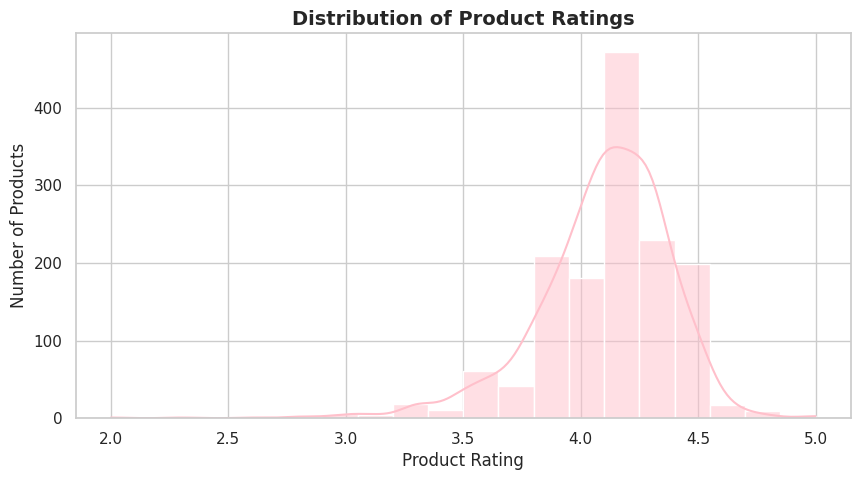

In [11]:
sns.set_theme(style='whitegrid',palette="Set1")
plt.figure(figsize=(10, 5))
sns.histplot(df['rating_num'], bins=20, kde=True, color='pink')

# Labels and Title
plt.title('Distribution of Product Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Product Rating', fontsize=12)
plt.ylabel('Number of Products', fontsize=12)

# Save and Display
plt.savefig('ratings_dist.png', bbox_inches='tight')
plt.show()

### ***Price vs Rating***

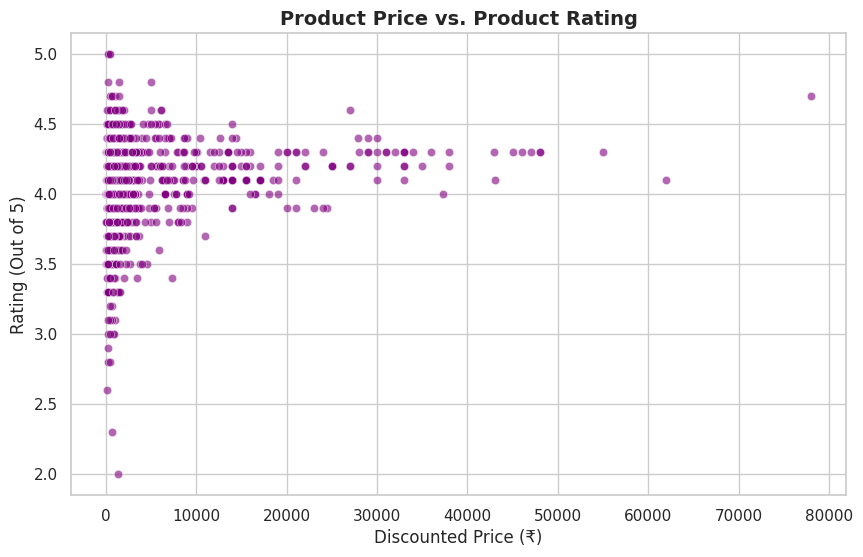

In [12]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='discounted_price_num',
    y='rating_num',
    alpha=0.6,
    color='purple',
)

plt.title('Product Price vs. Product Rating', fontsize=14, fontweight='bold')
plt.xlabel('Discounted Price (₹)', fontsize=12)
plt.ylabel('Rating (Out of 5)', fontsize=12)

plt.savefig('price_vs_rating.png', bbox_inches='tight')
plt.show()

### ***Distribution of Discount Percentages***

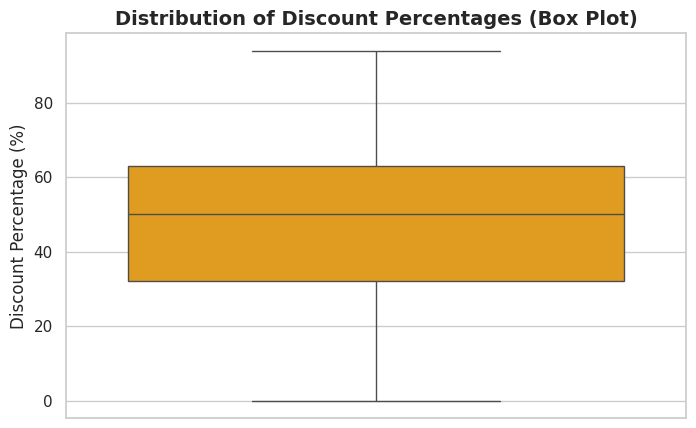

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=df['discount_pct_num'], color='orange')

plt.title(
    'Distribution of Discount Percentages (Box Plot)',
    fontsize=14,
    fontweight='bold',
)
plt.ylabel('Discount Percentage (%)', fontsize=12)

plt.savefig('discount_boxplot.png', bbox_inches='tight')
plt.show()

### ***Coorelation Heatmap***

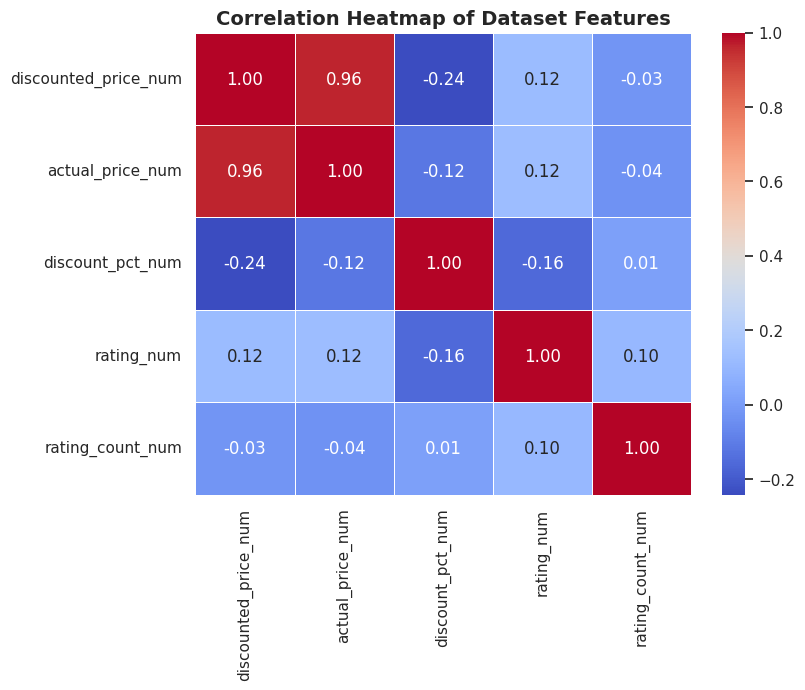

In [14]:
# Select numerical columns
num_cols = [
    'discounted_price_num',
    'actual_price_num',
    'discount_pct_num',
    'rating_num',
    'rating_count_num',
]
corr_matrix = df[num_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

plt.title('Correlation Heatmap of Dataset Features', fontsize=14, fontweight='bold')

plt.savefig('correlation_heatmap.png', bbox_inches='tight')
plt.show()